# Grant figure: a morphological signature of NF1 deficiency in Schwann cells

A single, self-contained notebook that builds the three-panel Preliminary Data figure.
Nothing is stitched together from existing figure files: every panel is regenerated here from raw images or model outputs.

| Panel | Shows | Source |
|:--|:--|:--|
| **A** | Cell Painting montage of one WT and one *NF1*-null Schwann cell | Raw Plate 5 images from [figshare](https://doi.org/10.6084/m9.figshare.26759914) (only 8 TIFFs are fetched, via HTTP range requests) |
| **B** | Original model applied to a new clone of the isogenic lines (Plate 6): reduced performance | `3.assess_generalizability/results/plate_6_single_cell_probabilities_qc.parquet` |
| | *(B also draws the retrained model that includes the new clone: performance rescued)* | `1.train_models/train_deriv_model/data/nf1_model_pre_evaluation_results.parquet` |
| **C** | The signature is multifaceted: strongest feature in every compartment x feature group x channel block | `1.train_models/train_deriv_model/coeff_results/final_model_coefficients.csv` |

**Running it.** Run from this notebook's folder (`4.figures/grant_figure/`); it finds the repo root automatically.
Outputs go to `./output/` (PDF + 1200 dpi PNG), and a 600 dpi PNG for the README is written to `4.figures/figures/grant_figure.png`.
Downloaded images and counts are cached in `./data/`.

**Requirements.** Network access on the first run (figshare and GitHub), and Python packages `numpy`, `pandas`, `scipy`, `scikit-learn`, `pyarrow`, `requests`, `tifffile`, `fsspec` + `aiohttp`, and `matplotlib` >= 3.8 (for bold-italic maths text).

## Setup

In [1]:
import io
import pathlib
import zipfile

import fsspec
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import requests
import tifffile
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy import ndimage as ndi
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

/Users/waygr/miniconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# ---- locate the repo and set paths -------------------------------------------------
def find_repo_root(start=None):
    """Walk up from the working directory until the folder holding the analysis modules is found."""
    here = pathlib.Path(start or pathlib.Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "1.train_models").is_dir() and (p / "3.assess_generalizability").is_dir():
            return p
    raise FileNotFoundError("Run this notebook from inside the NF1 analysis repo.")

REPO = find_repo_root()
DATA_DIR = pathlib.Path("data")      # cache for downloaded images / metadata
OUT_DIR = pathlib.Path("output")     # final figure files
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

# Model outputs already in the repo
P6_ORIGINAL_MODEL = REPO / "3.assess_generalizability/results/plate_6_single_cell_probabilities_qc.parquet"
RETRAINED_EVAL = REPO / "1.train_models/train_deriv_model/data/nf1_model_pre_evaluation_results.parquet"
COEFFICIENTS = REPO / "1.train_models/train_deriv_model/coeff_results/final_model_coefficients.csv"

# Panel A inputs (public)
PLATE5_PROFILES_URL = (
    "https://github.com/WayScience/nf1_cellpainting_data/raw/main/3.processing_features/"
    "data/single_cell_profiles/Plate_5_sc_annotated.parquet"
)
PLATE5_ZIP_URL = "https://ndownloader.figshare.com/files/48623125"  # doi:10.6084/m9.figshare.26759914
print("repo:", REPO)

repo: /Users/waygr/repos/wayscience/NF1_SchwannCell_data_analysis


In [3]:
# ---- figure-wide style -------------------------------------------------------------
FIG_W = 6.57                     # inches; the height follows from the layout below
DPI = 1200                       # raster resolution of the PNG and of the microscopy images embedded in the PDF

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Helvetica Neue", "DejaVu Sans"],
    "font.size": 7,
    "axes.linewidth": 0.6,
    "axes.labelsize": 7,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.major.pad": 2,
    "ytick.major.pad": 2,
    "axes.labelpad": 1.5,
    "legend.fontsize": 6.5,
    "mathtext.default": "regular",
    "pdf.fonttype": 42,          # keep text editable / embedded as TrueType
})

# Okabe-Ito colour-blind-safe pair: colour = clone, line style = model (panels B and C)
COL_ORIGINAL = "#0072B2"
COL_NEW = "#D55E00"
CLONE_COLOR = {"original": COL_ORIGINAL, "new": COL_NEW}
CLONE_LABEL = {"original": "Original clone", "new": "New clone"}
MODEL_STYLE = {"original": (0, (3.2, 1.6)), "retrained": "-"}    # dashed = original model, solid = retrained
MODEL_LABEL = {"original": "Original model", "retrained": "Retrained model"}
CURVE_LW = 1.3                                                  # line width of the plotted precision-recall curves

# Cell Painting channel -> (label, display colour, text colour); order = montage column order
CHANNELS = {
    "DAPI": ("Nuclei",        (0.25, 0.45, 1.00), "#2750d8"),
    "GFP":  ("ER",            (0.00, 1.00, 0.25), "#0a8a2e"),
    "CY5":  ("Mitochondria",  (1.00, 0.00, 1.00), "#b800b8"),
    "RFP":  ("Actin",         (1.00, 0.12, 0.12), "#d01818"),
}
CHANNEL_TEXT_COLOR = [c[2] for c in CHANNELS.values()]          # same order as CHANNELS

## Panel A: Cell Painting montage

**Cell choice.** We reuse the manuscript's two example cells (random seed 58 on Plate 5, one cell per genotype) so the grant figure matches the paper.

**Images.** Raw TIFFs are read straight out of the 7 GB figshare `Plate_5.zip` using HTTP range requests (only the zip index and the 8 needed files are transferred, ~20 MB).

**Illumination correction.** The repo's CellProfiler pipeline (`NF1_illum_4channel.cppipe`) estimates the illumination function *per image* (Background method, polynomial smoothing, per-channel block size) and subtracts it.
Because it is per image, it can be reproduced here without the rest of the plate: block-wise minimum, polynomial fit, subtraction, clip at zero.

**Display.** Each channel uses *one* intensity range shared by both genotypes (99.8th percentile of the pooled corrected fields), so brightness differences between cells are real, not an artefact of per-tile auto-contrast.

In [4]:
# ---- 1. reproduce the manuscript's two example cells --------------------------------
SEED = 58          # manuscript seed that gives non-mitotic, non-dying example cells
CROP = 250         # crop edge in pixels (~80 um)
PIXEL_UM = 394 / 1224      # um per pixel, from the image metadata (394 um field width, 1224 px, 20x)

profiles_cache = DATA_DIR / "plate5_cell_locations.parquet"
if not profiles_cache.exists():
    profile_cols = [
        "Metadata_Well", "Metadata_Site", "Metadata_genotype",
        "Metadata_Nuclei_Location_Center_X", "Metadata_Nuclei_Location_Center_Y",
    ]
    # downloads the Plate 5 profile table (~120 MB) once and keeps only the cell locations
    pd.read_parquet(PLATE5_PROFILES_URL, columns=profile_cols).to_parquet(profiles_cache)
plate5 = pd.read_parquet(profiles_cache)
plate5 = plate5[plate5["Metadata_genotype"] != "HET"]   # HET was not used for modelling

example_cells = {}
for genotype in ["WT", "Null"]:
    row = plate5[plate5["Metadata_genotype"] == genotype].sample(1, random_state=SEED).iloc[0]
    example_cells[genotype] = {
        "well": row["Metadata_Well"],
        "site": int(row["Metadata_Site"]),
        "x": float(row["Metadata_Nuclei_Location_Center_X"]),
        "y": float(row["Metadata_Nuclei_Location_Center_Y"]),
    }
print(example_cells)
# the manuscript's cells were WT: E2 site 13 and Null: F10 site 12
assert (example_cells["WT"]["well"], example_cells["WT"]["site"]) == ("E2", 13)
assert (example_cells["Null"]["well"], example_cells["Null"]["site"]) == ("F10", 12)

{'WT': {'well': 'E2', 'site': 13, 'x': 536.9815043156597, 'y': 146.00123304562268}, 'Null': {'well': 'F10', 'site': 12, 'x': 602.9166221272047, 'y': 232.64778193479424}}


In [5]:
# ---- 2. fetch just the needed TIFFs from the figshare zip ---------------------------
class HTTPRangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP range requests, so `zipfile` can read a remote zip."""

    def __init__(self, url):
        self.session, self.src, self.pos = requests.Session(), url, 0
        self._resolve()

    def _resolve(self):
        # figshare redirects to a presigned S3 URL that expires after ~10 s, so re-resolve when needed
        r = self.session.get(self.src, headers={"Range": "bytes=0-0"}, stream=True)
        self.url, self.size = r.url, int(r.headers["Content-Range"].split("/")[1])
        r.close()

    def seekable(self): return True
    def readable(self): return True
    def tell(self): return self.pos

    def seek(self, offset, whence=0):
        self.pos = {0: offset, 1: self.pos + offset, 2: self.size + offset}[whence]
        return self.pos

    def read(self, n=-1):
        n = self.size - self.pos if n < 0 else min(n, self.size - self.pos)
        if n <= 0:
            return b""
        headers = {"Range": f"bytes={self.pos}-{self.pos + n - 1}"}
        r = self.session.get(self.url, headers=headers)
        if r.status_code == 403:      # presigned URL expired
            self._resolve()
            r = self.session.get(self.url, headers=headers)
        r.raise_for_status()
        self.pos += len(r.content)
        return r.content

    def readinto(self, b):
        data = self.read(len(b))
        b[: len(data)] = data
        return len(data)

CHANNEL_INDEX = {"DAPI": 1, "GFP": 2, "CY5": 3, "RFP": 4}    # position in the Cytation file names

def tiff_name(cell, channel):
    return f"{cell['well']}_01_{CHANNEL_INDEX[channel]}_{cell['site']}_{channel}_001.tif"

needed = [tiff_name(c, ch) for c in example_cells.values() for ch in CHANNELS]
missing = [n for n in needed if not (DATA_DIR / n).exists()]
if missing:
    with zipfile.ZipFile(HTTPRangeFile(PLATE5_ZIP_URL)) as zf:
        for name in missing:
            (DATA_DIR / name).write_bytes(zf.read(name))
            print("downloaded", name)
print(f"{len(needed)} raw images available in {DATA_DIR}/")

8 raw images available in data/


In [6]:
# ---- 3. illumination correction (per image; mirrors NF1_illum_4channel.cppipe) -----
BLOCK_SIZE = {"DAPI": 50, "GFP": 50, "CY5": 15, "RFP": 15}    # pixels, from the pipeline

def illumination_correct(img16, block):
    """Background illumination estimate (block minimum + 2nd-order polynomial) subtracted from the image."""
    x = img16.astype(np.float64) / 65535.0
    h, w = x.shape
    nby, nbx = -(-h // block), -(-w // block)
    padded = np.pad(x, ((0, nby * block - h), (0, nbx * block - w)), mode="edge")
    block_min = padded.reshape(nby, block, nbx, block).min(axis=(1, 3))
    background = ndi.zoom(block_min, (h / nby, w / nbx), order=3, mode="nearest")[:h, :w]
    background = np.clip(background, block_min.min(), block_min.max())
    yy, xx = np.mgrid[0:h, 0:w]
    u, v = xx / (w - 1) * 2 - 1, yy / (h - 1) * 2 - 1
    design = np.stack([np.ones_like(u), u, v, u * u, u * v, v * v], -1).reshape(-1, 6)
    coef, *_ = np.linalg.lstsq(design, background.reshape(-1), rcond=None)
    fit = np.clip((design @ coef).reshape(h, w), block_min.min(), block_min.max())
    return np.clip(x - fit, 0, 1)

corrected = {
    (g, ch): illumination_correct(tifffile.imread(DATA_DIR / tiff_name(c, ch)), BLOCK_SIZE[ch])
    for g, c in example_cells.items()
    for ch in CHANNELS
}
# one display range per channel, shared by both genotypes
display_max = {
    ch: np.percentile(np.concatenate([corrected[g, ch].ravel() for g in example_cells]), 99.8)
    for ch in CHANNELS
}
print({ch: round(v, 3) for ch, v in display_max.items()})

{'DAPI': np.float64(0.523), 'GFP': np.float64(0.693), 'CY5': np.float64(0.755), 'RFP': np.float64(0.544)}


In [7]:
# ---- 4. crop, upsample to print resolution, colourise ------------------------------
TILE_IN = 1.18                                   # printed tile edge (inches), set by the layout below
UPSAMPLE = TILE_IN * DPI / CROP                  # so every tile is ~DPI pixels per printed inch

def crop_at(img, cx, cy, n):
    h, w = img.shape
    x0 = int(round(min(max(cx - n / 2, 0), w - n)))
    y0 = int(round(min(max(cy - n / 2, 0), h - n)))
    return img[y0:y0 + n, x0:x0 + n]

def tile_for(genotype, channel):
    cell = example_cells[genotype]
    t = crop_at(corrected[genotype, channel], cell["x"], cell["y"], CROP) / display_max[channel]
    t = np.clip(ndi.zoom(np.clip(t, 0, 1), UPSAMPLE, order=3), 0, 1)       # smooth, crisp upsampling
    return t[..., None] * np.array(CHANNELS[channel][1])

montage = {}
for g in example_cells:
    tiles = [tile_for(g, ch) for ch in CHANNELS]
    composite = 1 - np.prod([1 - t for t in tiles], axis=0)                  # screen blend limits white-out
    montage[g] = tiles + [composite]
print("tile size (px):", montage["WT"][0].shape[:2])

tile size (px): (1416, 1416)


## Panel B: generalization to a new clone, and the rescue by retraining

Both models are scored on **exactly the same cells** and drawn on **shared axes** (colour = clone, line style = model), so the drop and the recovery read as one direct comparison.

* **Original model (dashed).** Trained without Plate 6. Plate 6 contains the original clones (iNFixion: A3 WT, C04 null) and the new clones made with a different protocol (MGH: GFP 3 WT, C23 null). The model has never seen these cells. We use the repo's QC-filtered predictions, HET cells excluded.
* **Retrained model (solid).** Same algorithm, retrained with Plate 6 included. The curves use the model's **out-of-fold cross-validation predictions**.
  The held-out test wells for the new clone contain a single genotype (58 WT cells, no nulls), so no precision-recall curve can be computed on them.
  The cross-validation folds were drawn at random across cells, so cells from one well can sit on both sides of a split: the retrained curves are somewhat optimistic relative to a well-level hold-out.

The two outputs cover slightly different cell sets (the retrained model's cross-validation set is down-sampled by genotype), and precision-recall curves depend on class balance.
To keep the comparison fair, the notebook scores both models on the cells present in both files (matched on well, site, and cell number).

The hyperparameter search stored 500 sets of out-of-fold predictions (one per random draw of the regularisation strength, all covering the same cells).
As in the training script, the draw with the highest cross-validated accuracy is used: the one that defines the final model.

In [8]:
KEY = ["Metadata_Well", "Metadata_Site", "Metadata_Cells_Number_Object_Number"]
CLONE_OF = {"iNFixion": "original", "MGH": "new"}      # Plate 6 institution -> clone

# ---- original model: Plate 6 predictions (never seen during training) ----------------
orig = pd.read_parquet(P6_ORIGINAL_MODEL)
shuffled = orig[(orig["data_type"] == "shuffled") & orig["Metadata_genotype"].isin(["WT", "Null"])]
orig = orig[(orig["data_type"] == "final") & orig["Metadata_genotype"].isin(["WT", "Null"])]
orig = orig[KEY + ["probability_WT", "true_genotype"]].rename(
    columns={"probability_WT": "p_original", "true_genotype": "label_original_file"})

# chance check: the same model with shuffled features
for inst, g in shuffled.groupby("Metadata_Institution"):
    print(f"shuffled-feature control, {CLONE_OF[inst]:8s} clone: AUROC {roc_auc_score(g['Metadata_genotype'] == 'WT', g['probability_WT']):.2f}")

# ---- retrained model: out-of-fold predictions ----------------------------------------
eval_cols = ["probability_WT", "true_genotype", "Metadata_Plate", "Metadata_Institution", "datasplit"] + KEY
val = pq.read_table(RETRAINED_EVAL, columns=eval_cols, filters=[("datasplit", "==", "val")]).to_pandas()

N_DRAWS = 500
n_cells = len(val) // N_DRAWS
assert n_cells * N_DRAWS == len(val)
prob = val["probability_WT"].to_numpy().reshape(N_DRAWS, n_cells)
truth = val["true_genotype"].to_numpy().reshape(N_DRAWS, n_cells)
assert (truth == truth[0]).all()                       # every draw covers the same cells in the same order

# select the draw with the best cross-validated accuracy (the training script's criterion for the final model)
draw_accuracy = ((prob > 0.5) == truth).mean(axis=1)
best_draw = int(draw_accuracy.argmax())
print(f"retrained model: best draw #{best_draw}, out-of-fold accuracy {draw_accuracy[best_draw]:.3f} "
      f"(range across draws {draw_accuracy.min():.3f}-{draw_accuracy.max():.3f})")
oof = val.iloc[best_draw * n_cells:(best_draw + 1) * n_cells]
oof = oof[oof["Metadata_Plate"] == "Plate_6"]
oof = oof[KEY + ["probability_WT", "true_genotype", "Metadata_Institution"]].rename(columns={"probability_WT": "p_retrained"})

# ---- score both models on the same cells ---------------------------------------------
scored = oof.merge(orig, on=KEY, how="inner", validate="one_to_one")
assert (scored["true_genotype"] == scored["label_original_file"]).all()       # both files agree on every cell's genotype
scored["clone"] = scored["Metadata_Institution"].map(CLONE_OF)
print(f"cells in retrained CV set: {len(oof)}, original-model set: {len(orig)}, scored by both: {len(scored)}")

curves, metrics = {}, []
for clone, g in scored.groupby("clone"):
    y = g["true_genotype"].to_numpy()
    for model, col in [("original", "p_original"), ("retrained", "p_retrained")]:
        p = g[col].to_numpy()
        curves[model, clone] = (y, p)
        metrics.append({"model": model, "clone": clone, "cells": len(y), "WT fraction": round(y.mean(), 2),
                        "AUPRC": round(average_precision_score(y, p), 3), "AUROC": round(roc_auc_score(y, p), 3)})
metrics = pd.DataFrame(metrics)
metrics

shuffled-feature control, new      clone: AUROC 0.51
shuffled-feature control, original clone: AUROC 0.49


retrained model: best draw #95, out-of-fold accuracy 0.803 (range across draws 0.801-0.803)
cells in retrained CV set: 3116, original-model set: 4276, scored by both: 3025


,model,clone,cells,WT fraction,AUPRC,AUROC
0,original,new,2078,0.47,0.460,0.494
1,retrained,new,2078,0.47,0.912,0.927
2,original,original,947,0.60,0.831,0.777
3,retrained,original,947,0.60,0.851,0.807


## Panel C: the signature is multifaceted

The retrained model has 834 morphology features. Following the manuscript's coefficient figure, every feature is assigned to a block defined by three things:
**cell compartment** (nucleus, cytoplasm, whole cell), **feature group** (radial distribution, texture, intensity, granularity, correlation, area/shape), and **channel** (the stain it was measured on).
Each block shows its **strongest feature's absolute coefficient**, so the whole signature is summarised in one view and "is it concentrated in one place?" is answered at a glance.
Correlation features compare two channels and shape features use no stain, so those two rows are not split by channel (one cell spans all four channels).
The two strongest blocks are outlined in red, as in the manuscript.

In [9]:
coef = pd.read_csv(COEFFICIENTS)
parts = coef["feature"].str.split("_", expand=True)
coef["compartment"], coef["feature_group"], coef["channel"] = parts[0], parts[1], parts[3]
coef["weight"] = coef["coefficient"].abs()
coef["feature_group"] = coef["feature_group"].replace({"Neighbors": "AreaShape"})     # one feature; grouped with shape

COMPARTMENTS = ["Nuclei", "Cytoplasm", "Cells"]                    # CellProfiler object names
COMPARTMENT_LABELS = ["Nucleus", "Cytoplasm", "Whole cell"]        # shown in the figure
CHANNEL_NAME = {"DAPI": "Nuclei", "GFP": "ER", "CY5": "Mito", "RFP": "Actin"}
CHANNEL_ORDER = ["Nuclei", "ER", "Mito", "Actin"]
ROWS = [   # (feature group, label, split by channel?)
    ("RadialDistribution", "Radial dist.", True),
    ("Texture", "Texture", True),
    ("Intensity", "Intensity", True),
    ("Granularity", "Granularity", True),
    ("Correlation", "Correlation", False),
    ("AreaShape", "Area / shape", False),
]
coef["block_channel"] = np.where(
    coef["feature_group"].isin(["Correlation", "AreaShape"]), "all", coef["channel"].map(CHANNEL_NAME)
)
assert coef["block_channel"].notna().all()

top_feature = coef.groupby(["compartment", "feature_group", "block_channel"])["weight"].max()
single = top_feature[top_feature.index.get_level_values("block_channel") != "all"]
top_blocks = set(single.nlargest(2).index)                                   # outlined in red in the figure
print(f"{len(coef)} features in {len(top_feature)} blocks; strongest blocks:")
print(top_feature.nlargest(5).round(2).to_string())

834 features in 47 blocks; strongest blocks:
compartment  feature_group       block_channel
Nuclei       RadialDistribution  Nuclei           2.18
                                 Actin            1.99
Cytoplasm    Intensity           Nuclei           1.63
Cells        Correlation         all              1.53
Cytoplasm    RadialDistribution  Actin            1.23


## Cells profiled per clone (printed on the nuclei images in panel A)

Single cells that passed quality control and feature selection, counted from the cleaned single-cell profiles of every plate in the study (Plates 3, 3 prime, 5 and 6), with no down-sampling.
Panel A shows the original clones (A3 WT, C04 null; iNFixion).
As a check, Plates 3, 3 prime and 5 together hold 20,680 WT and null cells, the total quoted in the repo README.

In [10]:
PROFILES_BASE = ("https://github.com/WayScience/nf1_cellpainting_data/raw/main/3.processing_features/"
                 "data/single_cell_profiles/cleaned_sc_profiles/")
PLATES = ["Plate_3", "Plate_3_prime", "Plate_5", "Plate_6"]

counts_cache = DATA_DIR / "cells_profiled_per_clone.csv"
if not counts_cache.exists():          # reads only the metadata columns of each (large) file
    rows = []
    for plate in PLATES:
        with fsspec.open(f"{PROFILES_BASE}{plate}_sc_feature_selected.parquet", "rb") as f:
            pf = pq.ParquetFile(f)
            meta_cols = [c for c in ["Metadata_genotype", "Metadata_Institution"] if c in pf.schema_arrow.names]
            df = pf.read(columns=meta_cols).to_pandas()
        if "Metadata_Institution" not in df:        # Plates 3, 3 prime and 5 contain only the original (iNFixion) clones
            df["Metadata_Institution"] = "iNFixion"
        rows.append(df.groupby(["Metadata_Institution", "Metadata_genotype"]).size()
                      .rename("cells").reset_index().assign(plate=plate))
    pd.concat(rows).to_csv(counts_cache, index=False)
cell_counts = pd.read_csv(counts_cache)

wt_null = cell_counts[cell_counts["Metadata_genotype"].isin(["WT", "Null"])]
assert wt_null[wt_null["plate"].isin(["Plate_3", "Plate_3_prime", "Plate_5"])]["cells"].sum() == 20680

per_clone = cell_counts.groupby(["Metadata_Institution", "Metadata_genotype"])["cells"].sum()
cells_profiled = {g: int(per_clone["iNFixion", g]) for g in ["WT", "Null"]}      # original clones: A3 (WT), C04 (null)
print("cells profiled per original clone:", cells_profiled)
cell_counts.pivot_table(index=["plate", "Metadata_Institution"], columns="Metadata_genotype", values="cells", aggfunc="sum")

cells profiled per original clone: {'WT': 10785, 'Null': 11406}


Metadata_genotype                      HET    Null      WT
plate         Metadata_Institution                        
Plate_3       iNFixion                 NaN  5558.0  4648.0
Plate_3_prime iNFixion                 NaN  2188.0  2938.0
Plate_5       iNFixion                 NaN  3154.0  2194.0
Plate_6       MGH                   1712.0  1145.0  1742.0
              iNFixion               752.0   506.0  1005.0

## Assemble the figure

grant_figure -> [6.57 4.72] in


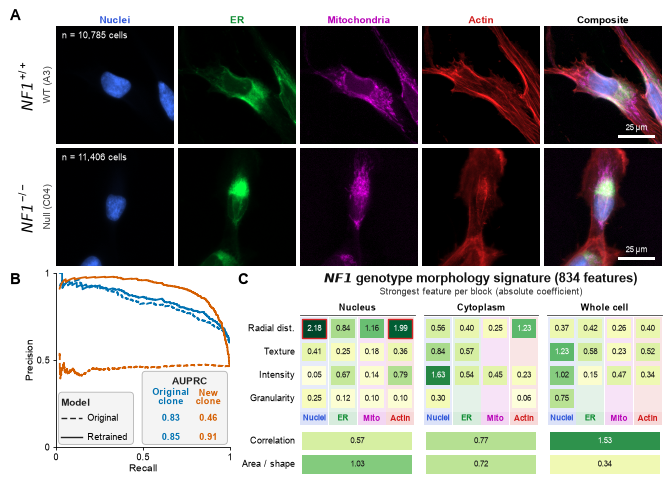

In [11]:
LETTER = dict(fontsize=11, fontweight="bold", va="top", ha="left")

def pr_xy(y, p, min_recall=0.02):
    """Precision-recall curve without sklearn's artificial (recall 0, precision 1) end point."""
    precision, recall, _ = precision_recall_curve(y, p)
    precision, recall = precision[:-1], recall[:-1]
    keep = recall >= min_recall            # curves start at 2% recall: before that, a handful of cells set the precision
    return recall[keep], precision[keep]

auprc = {k: average_precision_score(*v) for k, v in curves.items()}


LEGEND_LW = 1.0                                         # line width of the sample lines in B's legend
README_DPI = 600                                        # resolution of the copy of the figure used in the README


def build_figure(column_tint=True):
    # ---- geometry (inches) --------------------------------------------------------
    gap, tile = 0.04, TILE_IN
    pitch = tile + gap
    head, a_h = 0.18, 2 * tile + gap                    # column headers, two rows of tiles
    side, foot = 0.03, 0.31                             # right margin, tick labels + axis label under the bottom row
    plot_h = 1.74                                       # bottom row height = side of the square PR plot
    fig_h = head + a_h + 0.07 + plot_h + foot + 0.02
    fig = plt.figure(figsize=(FIG_W, fig_h))

    def ax_in(left, bottom, width, height, **kw):
        return fig.add_axes([left / FIG_W, bottom / fig_h, width / FIG_W, height / fig_h], **kw)

    def put(x, y, s, **kw):                             # text at inch coordinates
        return fig.text(x / FIG_W, y / fig_h, s, **kw)

    bot = foot + 0.02                                   # bottom of the bottom-row axes
    top_row = bot + plot_h                              # top of the bottom-row axes

    # ---- Panel A: montage ---------------------------------------------------------
    x0 = FIG_W - 5 * tile - 4 * gap - side              # left edge of the tile grid; B and C align to it
    a_top = fig_h - head
    put(0.02, fig_h - 0.01, "A", **LETTER)
    row_label = {"WT": (r"$\mathit{NF1}^{+/+}$", "WT (A3)"), "Null": (r"$\mathit{NF1}^{-/-}$", "Null (C04)")}
    col_names = [CHANNELS[ch][0] for ch in CHANNELS] + ["Composite"]
    col_colors = CHANNEL_TEXT_COLOR + ["black"]
    for r, g in enumerate(["WT", "Null"]):
        bottom = a_top - (r + 1) * tile - r * gap
        put(x0 - 0.285, bottom + tile / 2, row_label[g][0], rotation=90, ha="center", va="center", fontsize=11)
        put(x0 - 0.085, bottom + tile / 2, row_label[g][1], rotation=90, ha="center", va="center",
            fontsize=7, color="#444444")
        for c, t in enumerate(montage[g]):
            ax = ax_in(x0 + c * pitch, bottom, tile, tile)
            ax.imshow(t, interpolation="nearest", aspect="equal")
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            if r == 0:
                ax.set_title(col_names[c], fontsize=7.5, fontweight="bold", color=col_colors[c], pad=2)
            if c == 0:                                  # cells profiled for this clone
                ax.text(0.05, 0.955, f"n = {cells_profiled[g]:,} cells", transform=ax.transAxes, color="white",
                        fontsize=6.5, ha="left", va="top")
            if c == 4:                                  # 25 um scale bar on the composites
                bar = 25 / PIXEL_UM / CROP
                ax.add_patch(Rectangle((0.94 - bar, 0.055), bar, 0.022, transform=ax.transAxes, color="white", lw=0))
                ax.text(0.94 - bar / 2, 0.10, "25 µm", transform=ax.transAxes, color="white",
                        fontsize=6, ha="center", va="bottom")

    # ---- Panel B: precision-recall, both models on one square axes ----------------
    axB = ax_in(x0, bot, plot_h, plot_h)                # square, left edge aligned with the montage
    for model in ("original", "retrained"):            # retrained (solid) is drawn last, on top
        for clone in ("original", "new"):
            rec, prec = pr_xy(*curves[model, clone])
            axB.plot(rec, prec, color=CLONE_COLOR[clone], ls=MODEL_STYLE[model], lw=CURVE_LW, solid_capstyle="round")
    axB.set_xlim(0, 1); axB.set_ylim(0, 1)
    axB.set_xticks([0, 0.5, 1]); axB.set_xticklabels(["0", "0.5", "1"])
    axB.set_yticks([0, 0.5, 1]); axB.set_yticklabels(["0", "0.5", "1"])
    axB.set_xlabel("Recall"); axB.set_ylabel("Precision")
    for sp in ("top", "right"):
        axB.spines[sp].set_visible(False)
    def T(x, y, s, **kw):                               # text in axes-fraction coordinates
        return axB.text(x, y, s, transform=axB.transAxes, **kw)

    for bx, by, bw, bh in [(0.015, 0.015, 0.43, 0.30), (0.495, 0.015, 0.49, 0.42)]:    # two light-grey legend boxes
        axB.add_patch(FancyBboxPatch((bx, by), bw, bh, boxstyle="round,pad=0,rounding_size=0.02",
                                     transform=axB.transAxes, facecolor="#f4f4f4", edgecolor="#b3b3b3",
                                     lw=0.6, zorder=0.5, clip_on=False))
    xc = {"original": 0.66, "new": 0.875}               # AUPRC table column centres (axes fraction)
    T(0.7675, 0.375, "AUPRC", fontsize=7.2, fontweight="bold", color="#222222", ha="center", va="center")
    for clone in ("original", "new"):
        T(xc[clone], 0.29, CLONE_LABEL[clone].replace(" ", "\n"), fontsize=6.3, fontweight="bold",
          color=CLONE_COLOR[clone], ha="center", va="center", linespacing=1.0)
    T(0.03, 0.252, "Model", fontsize=7.2, fontweight="bold", color="#222222", va="center")
    for yy, model in [(0.165, "original"), (0.055, "retrained")]:
        ls = MODEL_STYLE[model]
        if not isinstance(ls, str):                      # keep the dash lengths of the plotted curves at the thinner width
            ls = (0, tuple(d * CURVE_LW / LEGEND_LW for d in ls[1]))
        axB.plot([0.03, 0.15], [yy, yy], transform=axB.transAxes, color="#222222", lw=LEGEND_LW,
                 ls=ls, clip_on=False)
        T(0.18, yy, MODEL_LABEL[model].split()[0], fontsize=6.5, va="center")
        for clone in ("original", "new"):
            T(xc[clone], yy, f"{auprc[model, clone]:.2f}", fontsize=6.8, fontweight="bold",
              color=CLONE_COLOR[clone], ha="center", va="center")
    put(0.02, top_row, "B", **LETTER)

    # ---- Panel C: compartment x feature group x channel ---------------------------
    gl = x0 + 2 * pitch                                 # grid spans tile columns 3-5 exactly
    gw = FIG_W - side - gl
    fgap, rgap = 0.09, 0.19                             # gap between compartments / gap holding the channel labels
    cwid = (gw - 2 * fgap) / 12
    band = 0.44                                         # title, subtitle and compartment headers above the grid
    cb = 0.04                                           # grid bottom: level with the bottom of B's axis label
    gh = top_row - band - cb
    rh = (gh - rgap) / len(ROWS)
    axC = ax_in(gl, cb, gw, gh)
    axC.set_xlim(0, gw); axC.set_ylim(0, gh); axC.axis("off")
    cmapC = mpl.colormaps["YlGn"]
    vmaxC = top_feature.max()
    pad = 0.022                                         # inset of each coefficient block (the lane behind it shows around it)

    def draw_block(x, y, w, h, value, outline=False):
        axC.add_patch(Rectangle((x + pad, y + pad), w - 2 * pad, h - 2 * pad,
                                facecolor=cmapC(value / vmaxC), edgecolor="none", lw=0))
        axC.text(x + w / 2, y + h / 2, f"{value:.2f}", ha="center", va="center", fontsize=5.8,
                 color="white" if value > 0.55 * vmaxC else "#1a1a1a")
        if outline:
            axC.add_patch(Rectangle((x + pad, y + pad), w - 2 * pad, h - 2 * pad, fill=False,
                                    edgecolor="#d62728", lw=1.0, zorder=5))

    for r, (grp, label, by_channel) in enumerate(ROWS):
        y = gh - (r + 1) * rh - (rgap if r >= 4 else 0)
        axC.text(-0.05, y + rh / 2, label, ha="right", va="center", fontsize=6.3)
        for f, comp in enumerate(COMPARTMENTS):
            fx = f * (4 * cwid + fgap)
            if by_channel:
                for c, ch in enumerate(CHANNEL_ORDER):
                    key = (comp, grp, ch)
                    if key in top_feature.index:
                        draw_block(fx + c * cwid, y, cwid, rh, top_feature[key], key in top_blocks)
            else:
                key = (comp, grp, "all")
                if key in top_feature.index:
                    draw_block(fx, y, 4 * cwid, rh, top_feature[key])
    for f, comp_label in enumerate(COMPARTMENT_LABELS):
        fx = f * (4 * cwid + fgap)
        axC.plot([fx, fx + 4 * cwid], [gh + 0.025] * 2, color="#444444", lw=0.6, clip_on=False)
        axC.text(fx + 2 * cwid, gh + 0.045, comp_label, ha="center", va="bottom", fontsize=6.8, fontweight="bold")
    # channel tags (and, optionally, lanes) tinted in the channel colour, flush under / behind each column of boxes
    tag_h, edge = 0.135, 0.004
    y_tag = gh - 4 * rh - 0.012 - tag_h
    for f in range(3):
        fx = f * (4 * cwid + fgap)
        for c, ch in enumerate(CHANNEL_ORDER):
            col = CHANNEL_TEXT_COLOR[c]
            if column_tint:      # light lane behind the four boxes of this channel (shows through gaps and empty cells)
                axC.add_patch(Rectangle((fx + c * cwid + edge, y_tag + tag_h), cwid - 2 * edge, gh - (y_tag + tag_h),
                                        facecolor=mpl.colors.to_rgba(col, 0.11), edgecolor="none", lw=0, zorder=0))
            axC.add_patch(Rectangle((fx + c * cwid + edge, y_tag), cwid - 2 * edge, tag_h,
                                    facecolor=mpl.colors.to_rgba(col, 0.16), edgecolor="none", lw=0, zorder=0))
            axC.text(fx + (c + 0.5) * cwid, y_tag + tag_h / 2, ch, ha="center", va="center", fontsize=6,
                     color=col, fontweight="bold")
    # title: the feature count is part of the same line, in the same size and weight
    title = r"$\mathbfit{NF1}$ genotype morphology signature" + f" ({len(coef)} features)"
    put(gl + gw / 2, top_row - 0.10, title, ha="center", va="baseline", fontsize=9.2, fontweight="bold",
        color="#111111")
    put(gl + gw / 2, top_row - 0.145, "Strongest feature per block (absolute coefficient)",
        ha="center", va="top", fontsize=6.8, color="#333333")
    put(gl - 0.62, top_row, "C", **LETTER)
    return fig

fig = build_figure()
fig.savefig(OUT_DIR / "grant_figure.png", dpi=DPI, facecolor="white")
fig.savefig(OUT_DIR / "grant_figure.pdf", dpi=DPI, facecolor="white")
fig.savefig(REPO / "4.figures" / "figures" / "grant_figure.png", dpi=README_DPI, facecolor="white")   # for the README
print("grant_figure ->", fig.get_size_inches().round(2), "in")
plt.show()

## Suggested figure legend

**Figure 1. A morphological signature of *NF1* deficiency in Schwann cells.**
**(A)** Cell Painting images of a wild-type (*NF1*<sup>+/+</sup>, A3) and an *NF1*-null (*NF1*<sup>-/-</sup>, C04) isogenic Schwann cell; the genotypes are not distinguishable by eye. The number of single cells profiled for each clone (all plates, after quality control) is given on the nuclei images. Scale bar, 25 µm; each channel is shown on the same intensity scale for both cells.
**(B)** Precision-recall curves for predicting *NF1* genotype from single-cell morphology, scored on the same cells from the original clones (blue) and a new clone of the same isogenic lines made with a different protocol (orange). The original model (dashed) performs well on the original clones but at chance on the new clone; retraining with the new clone included (solid) restores performance (out-of-fold predictions). AUPRC in the table.
**(C)** The signature is multifaceted: the 834 morphology features of the retrained model, summarised by the strongest feature (absolute coefficient) in each block of cell compartment, feature group and stain channel. Correlation and shape features are not channel-specific. Red outlines mark the two strongest blocks.